# Lab: Build a dense variational autoencoder for faces

**Time:** 90–120 minutes  
**Prerequisites:** PyTorch, linear layers, probability basics, and gradient descent

In this lab you will turn an image into a *distribution* in latent space, sample from
that distribution with the reparameterization trick, and train a decoder using the
VAE objective. The network is deliberately fully connected: convolution is useful
for images, but it is not what makes a model a VAE.

By the end, you should be able to:

- distinguish a deterministic autoencoder from a VAE;
- parameterize $q_\phi(z\mid x)$ with $\mu$ and $\log\sigma^2$;
- implement $z=\mu+\sigma\odot\epsilon$ without breaking backpropagation;
- combine reconstruction and KL-divergence terms; and
- generate new faces by sampling $z\sim\mathcal N(0,I)$.


**Vansh Joshi — revised work.** The assigned dense face architecture, LFW crop, identity balancing, split, model checks and loss checks are retained. Two fresh models compare β=0 and β=1 over ten epochs each.


**Provenance:** Completed from the official student template with AI assistance. All reported metrics and figures were produced by the executed cells; interpretations refer to those outputs.


## 1. Environment and LFW data (10 minutes)

This notebook runs both on Kaggle and locally.

**On Kaggle:** create a notebook, choose **Add Input**, search for `LFW Dataset`, and
attach the dataset whose mounted folder is `/kaggle/input/lfw-dataset`. Upload this
notebook or open it from the course repository, then choose a GPU accelerator if one
is available. No path edit should be necessary.

**Locally:** download and extract LFW so the directory contains person folders and
`.jpg` files. Then either:

1. set the environment variable `LFW_DATASET_PATH` to the extracted directory; or
2. edit `LOCAL_DATASET_PATH` in the next cell.

The path may point either directly to `lfw-deepfunneled` or to a parent directory;
the discovery code searches below it. The notebook fails early with a useful message
if no images are found.


In [1]:
# Kaggle images normally include these packages. For a minimal local environment:
# %pip install torch torchvision matplotlib pandas scikit-learn pillow

import os, json, platform
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(4)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
OUTPUT_DIR = Path("vae_faces_vansh_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

# Change only this line for a local setup if LFW_DATASET_PATH is not set.
LOCAL_DATASET_PATH = Path("data/lfw-deepfunneled")

print(f"Running on {DEVICE}")

print("PyTorch:", torch.__version__, "Python:", platform.python_version())
print("Seed:", SEED, "Epochs:", EPOCHS, "Batch size:", BATCH_SIZE)


Running on cuda
PyTorch: 2.10.0+cu128 Python: 3.13.11
Seed: 42 Epochs: 10 Batch size: 64


In [2]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend([
            Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
            Path("/kaggle/input/lfw-dataset"),
        ])
    candidates.extend([
        LOCAL_DATASET_PATH.expanduser(),
        Path("lfw-deepfunneled"),
    ])

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


DATASET_ROOT = resolve_lfw_root()
image_paths = sorted(DATASET_ROOT.rglob("*.jpg"))
image_df = pd.DataFrame({
    "path": image_paths,
    "person": [path.parent.name for path in image_paths],
})

# Preserve the original notebook's balancing choice: remove identities with 25+
# photographs so a few celebrities do not dominate reconstruction training.
image_df = image_df.groupby("person", group_keys=False).filter(lambda rows: len(rows) < 25)
image_df = image_df.reset_index(drop=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Using {len(image_df):,} images from {image_df['person'].nunique():,} people")
image_df.head()


Dataset root: <WORKSPACE>/work/data/lfw
Using 10,645 images from 5,707 people


,path,person
0,/home/vansh/Documents/Codex/2026-11-05/https-g...,AJ_Cook
1,/home/vansh/Documents/Codex/2026-11-05/https-g...,AJ_Lamas
2,/home/vansh/Documents/Codex/2026-11-05/https-g...,Aaron_Eckhart
3,/home/vansh/Documents/Codex/2026-11-05/https-g...,Aaron_Guiel
4,/home/vansh/Documents/Codex/2026-11-05/https-g...,Aaron_Patterson


Training faces: 8516 Validation faces: 2129


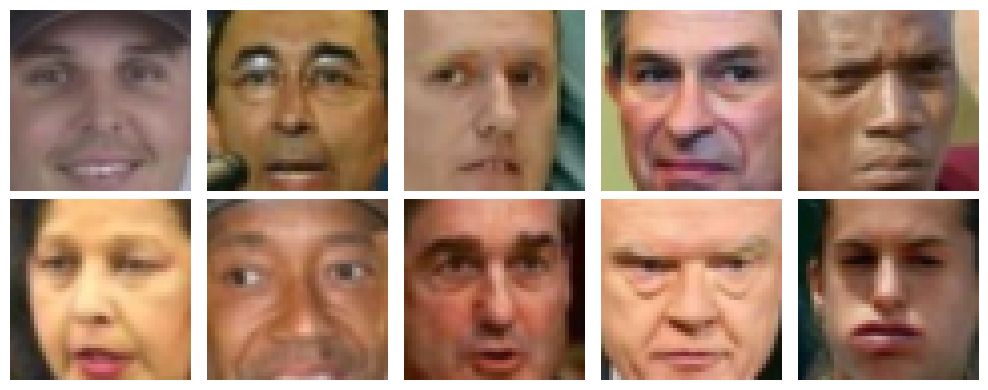

In [3]:
class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = self.dataframe.loc[index, "path"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # LFW deep-funneled images are 250x250. This reproduces the original
            # notebook's central crop while remaining safe for other image sizes.
            width, height = image.size
            margin_x = min(80, max(0, (width - 1) // 3))
            margin_y = min(80, max(0, (height - 1) // 3))
            image = image.crop((margin_x, margin_y, width - margin_x, height - margin_y))
            return self.transform(image)


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),  # pixel values in [0, 1]
])

train_df, val_df = train_test_split(image_df, test_size=0.2, random_state=SEED)
train_dataset = FaceDataset(train_df, transform)
val_dataset = FaceDataset(val_df, transform)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(train_dataset, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

faces = next(iter(train_loader))
assert faces.ndim == 4 and faces.shape[1:] == (3, 45, 45)
assert 0 <= faces.min() and faces.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(faces[:10], axes.flat):
    axis.imshow(face.permute(1, 2, 0))
    axis.axis("off")
plt.tight_layout()

print("Training faces:", len(train_dataset), "Validation faces:", len(val_dataset))


## 2. From autoencoder to VAE (10 minutes)

A deterministic autoencoder maps $x$ to one vector $z$. A VAE encoder instead
describes a diagonal Gaussian approximate posterior:

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

We predict `logvar` rather than variance because it may take any real value and is
numerically convenient. For a batch of `N` images and `LATENT_DIM = 100`, answer:

1. What are the shapes of `mu`, `logvar`, and `z`?
2. Why must the final `mu` and `logvar` layers have no ReLU?
3. Why does directly drawing `z` from a distribution parameterized by the encoder
   make ordinary backpropagation difficult?

Write your answers in a new Markdown cell.


### Section 2 answers

1. `mu`, `logvar`, and `z` each have shape **[N,100]**. They describe one diagonal Gaussian and one latent sample per face.
2. A ReLU would prevent negative means and would force log-variance ≥0 (variance ≥1). Linear heads allow either sign and variances both below and above one.
3. An ordinary random draw through `sample()` does not provide the needed pathwise derivative of the draw with respect to distribution parameters. Writing `z = mu + exp(0.5*logvar)*eps` moves randomness into parameter-independent `eps`; the remaining operations differentiate with respect to both heads.


## 3. Implement the probabilistic encoder (25 minutes)

**TODO 1:** Add two linear heads that map the shared 1000-unit representation to
`LATENT_DIM`: one for `mu` and one for `logvar`.

**TODO 2:** Implement the reparameterization trick. Compute
$\sigma=\exp(\tfrac12\log\sigma^2)$, draw $\epsilon$ with `torch.randn_like`, and
return $\mu+\sigma\epsilon$.

**TODO 3:** Complete `forward`: encode, sample, decode, and return
`reconstruction, mu, logvar`. The decoder returns probabilities in `[0, 1]`, so its
last operation is a sigmoid.


In [4]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )

        # TODO 1: define self.mu_head and self.logvar_head.
        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))
        return self.mu_head(features), self.logvar_head(features)

    def reparameterize(self, mu, logvar):
        # TODO 2: sample z while preserving a differentiable path to mu/logvar.
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        pixels = self.decoder(z)
        return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x):
        # TODO 3: encode x, sample z, decode it, and return all three outputs.
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


In [5]:
# These checks give fast feedback before expensive training.
model = DenseFaceVAE().to(DEVICE)
test_batch = faces[:4].to(DEVICE)
reconstruction, mu, logvar = model(test_batch)

assert reconstruction.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert reconstruction.min() >= 0 and reconstruction.max() <= 1

# Sampling should normally give different z values, while gradients still reach
# both distribution heads.
z1 = model.reparameterize(mu, logvar)
z2 = model.reparameterize(mu, logvar)
assert not torch.equal(z1, z2)
(z1.mean()).backward()
assert model.mu_head.weight.grad is not None
assert model.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("Model checks passed.")


Model checks passed.


## 4. Implement the negative ELBO (20 minutes)

For this Bernoulli observation model, minimize

$$
\mathcal L = \underbrace{\operatorname{BCE}(\hat x,x)}_{\text{reconstruction}}
+\beta\underbrace{D_{KL}\!\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)}_{\text{regularization}}.
$$

For a diagonal Gaussian,

$$D_{KL}=-\frac12\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

**TODO 4:** Compute BCE and KL with `reduction="sum"`, then divide each by the
batch size so reported values are per image. Return total loss, detached
reconstruction loss, and detached KL loss. Do not detach the total loss.


In [6]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
    # TODO 4: implement reconstruction + beta * KL, normalized per image.
    batch_size = target.size(0)
    reconstruction_term = F.binary_cross_entropy(reconstruction, target, reduction="sum") / batch_size
    kl_term = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum() / batch_size
    total = reconstruction_term + beta * kl_term
    return total, reconstruction_term.detach(), kl_term.detach()


In [7]:
# At mu=0 and logvar=0, q(z|x) equals the unit-normal prior, so KL must be zero.
dummy_x = torch.full((2, 3, 45, 45), 0.5, device=DEVICE)
dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
total, recon_term, kl_term = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(kl_term, torch.tensor(0.0, device=DEVICE))
assert total.requires_grad is False  # dummy tensors do not require gradients

# With model outputs, the total must carry a gradient path.
reconstruction, mu, logvar = model(test_batch)
total, _, _ = vae_loss(reconstruction, test_batch, mu, logvar, beta=BETA)
assert total.requires_grad
print("Loss checks passed.")


Loss checks passed.


## 5. Train the VAE (20–30 minutes)

**TODO 5:** Complete one training step: move the batch to the device, clear old
gradients, run the model, compute the VAE loss, backpropagate, and update parameters.

The reconstruction term sums over 6075 pixels, whereas KL sums over 100 latent
dimensions, so their magnitudes will differ. Track them separately. Ten epochs are a
starting point; reduce `EPOCHS` for a smoke test or increase it for better faces.


In [8]:
def train_step(model, batch, optimizer, beta):
    # TODO 5: implement one optimization step and return three Python floats.
    model.train()
    batch = batch.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    reconstruction, mu, logvar = model(batch)
    total, reconstruction_term, kl_term = vae_loss(reconstruction, batch, mu, logvar, beta)
    total.backward()
    optimizer.step()
    return total.item(), reconstruction_term.item(), kl_term.item()


Fresh beta=1.0 model, 21,536,275 parameters


beta=1.0, epoch 01 | train 3984.37 | val 3943.26 | recon 3928.61 | KL 14.66


beta=1.0, epoch 02 | train 3916.05 | val 3882.60 | recon 3865.62 | KL 16.98


beta=1.0, epoch 03 | train 3869.20 | val 3878.48 | recon 3861.91 | KL 16.57


beta=1.0, epoch 04 | train 3854.58 | val 3838.44 | recon 3820.35 | KL 18.10


beta=1.0, epoch 05 | train 3839.04 | val 3821.44 | recon 3802.33 | KL 19.11


beta=1.0, epoch 06 | train 3825.32 | val 3815.97 | recon 3798.54 | KL 17.43


beta=1.0, epoch 07 | train 3819.25 | val 3810.00 | recon 3791.95 | KL 18.05


beta=1.0, epoch 08 | train 3811.70 | val 3801.03 | recon 3783.38 | KL 17.65


beta=1.0, epoch 09 | train 3806.28 | val 3797.84 | recon 3781.39 | KL 16.45


beta=1.0, epoch 10 | train 3802.95 | val 3794.04 | recon 3777.70 | KL 16.34


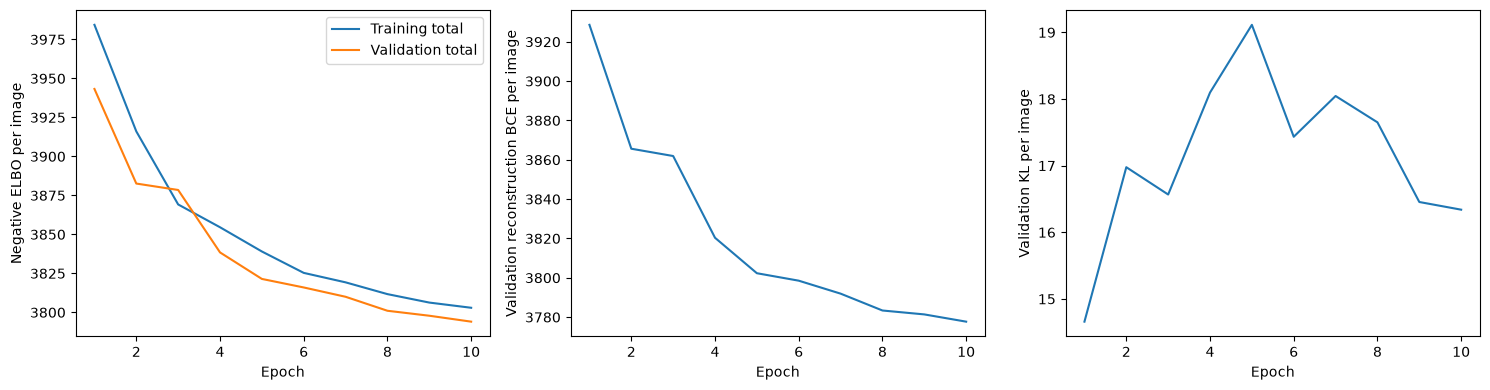

In [9]:
@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0
    # Fixed validation sampling noise makes the beta comparison repeatable and
    # leaves training RNG state unchanged.
    with torch.random.fork_rng(devices=[DEVICE.index or 0] if DEVICE.type == "cuda" else []):
        torch.manual_seed(2718)
        for batch in loader:
            batch = batch.to(DEVICE, non_blocking=True)
            reconstruction, mu, logvar = model(batch)
            values = vae_loss(reconstruction, batch, mu, logvar, beta)
            batch_size = batch.size(0)
            totals += np.array([value.item() for value in values]) * batch_size
            examples += batch_size
    return totals / examples

def train_fresh(beta):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    train_loader.generator.manual_seed(SEED)
    network = DenseFaceVAE().to(DEVICE)
    optimizer = torch.optim.Adam(network.parameters(), lr=LEARNING_RATE)
    history = {"train_total":[], "val_total":[], "val_reconstruction":[], "val_kl":[]}
    print(f"Fresh beta={beta} model, {sum(p.numel() for p in network.parameters()):,} parameters")
    for epoch in range(1,EPOCHS+1):
        network.train()
        running_total, seen = 0.0, 0
        for batch in train_loader:
            total, reconstruction_term, kl_term = train_step(network,batch,optimizer,beta)
            running_total += total*batch.size(0); seen += batch.size(0)
        val_total,val_reconstruction,val_kl = evaluate(network,val_loader,beta)
        history["train_total"].append(running_total/seen)
        history["val_total"].append(float(val_total))
        history["val_reconstruction"].append(float(val_reconstruction))
        history["val_kl"].append(float(val_kl))
        print(f"beta={beta}, epoch {epoch:02d} | train {running_total/seen:.2f} | val {val_total:.2f} | recon {val_reconstruction:.2f} | KL {val_kl:.2f}")
    return network,history

model,history = train_fresh(BETA)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(range(1,EPOCHS+1),history["train_total"],label="Training total")
axes[0].plot(range(1,EPOCHS+1),history["val_total"],label="Validation total")
axes[0].set_ylabel("Negative ELBO per image"); axes[0].legend()
axes[1].plot(range(1,EPOCHS+1),history["val_reconstruction"]); axes[1].set_ylabel("Validation reconstruction BCE per image")
axes[2].plot(range(1,EPOCHS+1),history["val_kl"]); axes[2].set_ylabel("Validation KL per image")
for ax in axes: ax.set_xlabel("Epoch")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"beta1_learning_curves.png",bbox_inches="tight"); plt.show()


## 6. Inspect reconstructions (10 minutes)

For a repeatable reconstruction we decode the posterior mean rather than a random
sample. Compare identity, pose, colour, and fine detail. Dense networks discard
spatial structure when flattening, so some blur is expected.

In the grid below, the **top row contains originals** and the **bottom row contains posterior-mean reconstructions**.


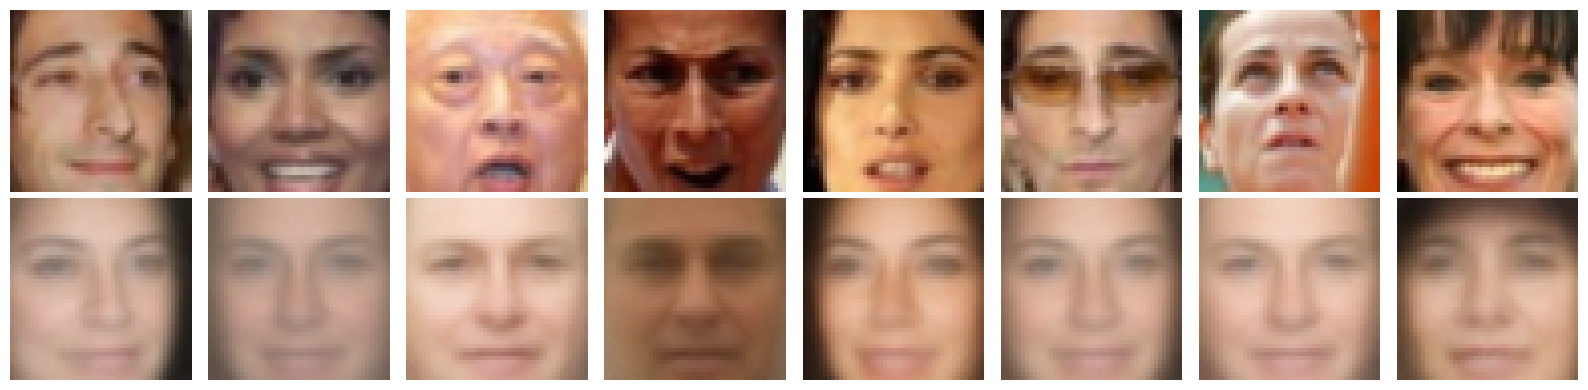

In [10]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu, _ = model.encode(validation_faces)
    reconstructed_faces = model.decode(mu)

originals = validation_faces.cpu()
reconstructed_faces = reconstructed_faces.cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for index in range(8):
    axes[0, index].imshow(originals[index].permute(1, 2, 0))
    axes[1, index].imshow(reconstructed_faces[index].permute(1, 2, 0).clamp(0, 1))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()

plt.savefig(OUTPUT_DIR/"beta1_reconstructions.png",bbox_inches="tight")
plt.show()


## 7. Generate new faces (10 minutes)

Reconstruction conditions on an existing face. Generation does not: it draws from
the prior and sends those latent vectors directly to the decoder.

**TODO 6:** Sample 10 latent vectors from $\mathcal N(0,I)$ on `DEVICE`, decode them,
and store the result in `generated_faces`. Then run the visualization cell.


In [11]:
model.eval()
with torch.no_grad():
    # TODO 6: sample from the prior and decode.
    torch.manual_seed(31415)
    prior_z = torch.randn(10, LATENT_DIM, device=DEVICE)
    generated_faces = model.decode(prior_z)


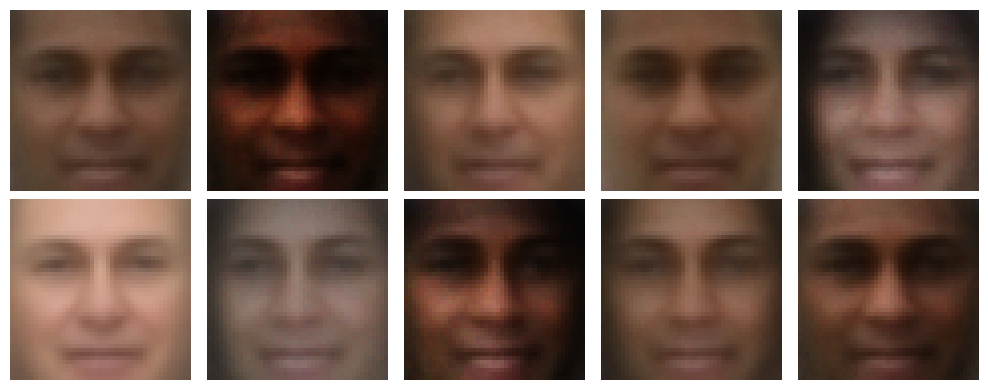

In [12]:
assert generated_faces.shape == (10, 3, 45, 45)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(generated_faces.cpu(), axes.flat):
    axis.imshow(face.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.tight_layout()

plt.savefig(OUTPUT_DIR/"beta1_prior_samples.png",bbox_inches="tight")
plt.show()


## 8. Experiment: what does $\beta$ control? (15–30 minutes)

Train fresh models using two of `BETA = 0`, `0.1`, `1`, or `4`, keeping all other
settings fixed. Record validation reconstruction, validation KL, and visual quality
of prior samples.

| $\beta$ | Reconstruction | KL | Prior-sample observations |
|---:|---:|---:|---|
| 0 | 3753.047 | 265.741 | Most prior samples are dark, with similar frontal outlines and limited visible variation; eyes and mouth are indistinct. |
| 1 | 3777.705 | 16.340 | More visible variation in illumination and colour, with clearer face-like structure; all samples still have soft eyes, mouths and fine detail. |

Answer in a Markdown cell:

1. What happens at $\beta=0$, and why is that model no longer encouraged to have a
   sampleable unit-normal latent space?
2. How does increasing $\beta$ change reconstruction fidelity and prior samples?
3. Why can a VAE be implemented without convolutional layers? What disadvantage does
   this dense model have for images?

### Optional extensions

- Interpolate between the posterior means of two validation faces and decode the path.
- Replace the dense encoder/decoder with convolutional layers without changing the
  probabilistic heads, reparameterization, or loss.
- Add KL warm-up: increase $\beta$ gradually from 0 to 1 during early epochs.


Fresh beta=0.0 model, 21,536,275 parameters


beta=0.0, epoch 01 | train 3959.76 | val 3872.76 | recon 3872.76 | KL 102.90


beta=0.0, epoch 02 | train 3851.42 | val 3813.78 | recon 3813.78 | KL 122.93


beta=0.0, epoch 03 | train 3814.56 | val 3794.42 | recon 3794.42 | KL 151.08


beta=0.0, epoch 04 | train 3796.82 | val 3784.04 | recon 3784.04 | KL 171.93


beta=0.0, epoch 05 | train 3784.62 | val 3784.75 | recon 3784.75 | KL 174.16


beta=0.0, epoch 06 | train 3778.18 | val 3780.39 | recon 3780.39 | KL 198.77


beta=0.0, epoch 07 | train 3775.11 | val 3763.61 | recon 3763.61 | KL 229.73


beta=0.0, epoch 08 | train 3786.92 | val 3774.22 | recon 3774.22 | KL 164.78


beta=0.0, epoch 09 | train 3773.80 | val 3767.63 | recon 3767.63 | KL 246.00


beta=0.0, epoch 10 | train 3768.84 | val 3753.05 | recon 3753.05 | KL 265.74


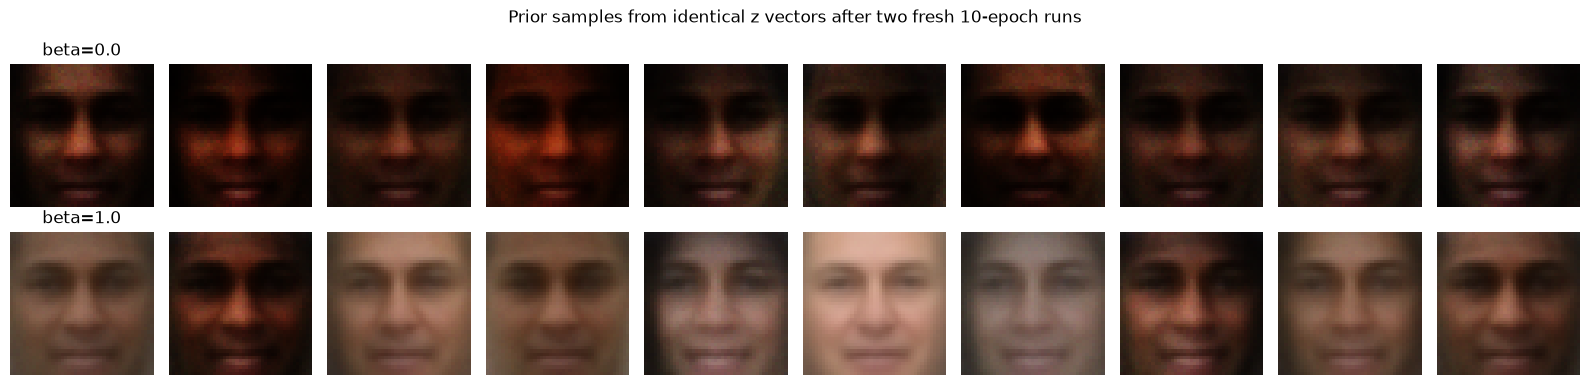

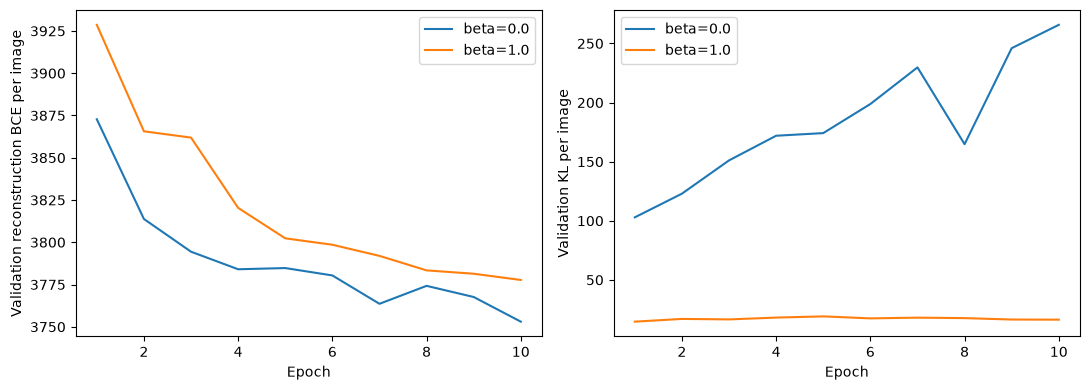

beta | validation reconstruction BCE per image | validation KL per image
0.0 | 3753.046564 | 265.740620
1.0 | 3777.704996 | 16.339656


2978

In [13]:
# BETA=1 above and BETA=0 here are both fresh initializations, with identical
# split, preprocessing, seed, minibatch order, optimizer, epochs and architecture.
beta_models={1.0:model}
beta_histories={1.0:history}
beta_models[0.0],beta_histories[0.0]=train_fresh(0.0)
fig,axes=plt.subplots(2,10,figsize=(16,4))
beta_results=[]
for row,beta in enumerate((0.0,1.0)):
    network=beta_models[beta]; network.eval()
    with torch.no_grad():
        # Use the same prior vectors to compare the two learned decoders.
        samples=network.decode(prior_z).cpu()
    for col in range(10):
        axes[row,col].imshow(samples[col].permute(1,2,0).clamp(0,1)); axes[row,col].axis("off")
        if col==0: axes[row,col].set_title(f"beta={beta}")
    h=beta_histories[beta]
    beta_results.append({"beta":beta,"val_reconstruction":h["val_reconstruction"][-1],"val_kl":h["val_kl"][-1],"val_total":h["val_total"][-1]})
plt.suptitle("Prior samples from identical z vectors after two fresh 10-epoch runs")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"beta_prior_comparison.png",bbox_inches="tight"); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for beta in (0.0,1.0):
    axes[0].plot(range(1,EPOCHS+1),beta_histories[beta]["val_reconstruction"],label=f"beta={beta}")
    axes[1].plot(range(1,EPOCHS+1),beta_histories[beta]["val_kl"],label=f"beta={beta}")
axes[0].set_ylabel("Validation reconstruction BCE per image"); axes[1].set_ylabel("Validation KL per image")
for ax in axes: ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"beta_comparison_curves.png",bbox_inches="tight"); plt.show()
print("beta | validation reconstruction BCE per image | validation KL per image")
for r in beta_results: print(f"{r['beta']} | {r['val_reconstruction']:.6f} | {r['val_kl']:.6f}")
(OUTPUT_DIR/"results.json").write_text(json.dumps({"seed":SEED,"epochs":EPOCHS,"train_faces":len(train_dataset),"validation_faces":len(val_dataset),"identities":int(image_df['person'].nunique()),"results":beta_results,"histories":beta_histories,"torch":torch.__version__,"device":str(DEVICE)},indent=2))


### Section 8 answers from the completed beta experiment

Both fresh models trained on **8,516 images**, with **2,129 validation images** after excluding identities with 25 or more photographs. This leaves **5,707 identities**. The split, architecture, learning rate 0.001, batch size 64, ten epochs, seed 42 and shuffled minibatch order are identical. Validation uses one fixed sampling-noise stream, and the comparison grid decodes the same ten prior vectors in both models. All reported BCE and KL values are per image.

1. **At beta=0, the loss ignores KL.** This model achieved validation reconstruction BCE **3753.047** and KL **265.741**. It can improve reconstruction while moving its posterior away from the unit-normal prior, because that mismatch has no penalty. The upper row of the prior comparison is mostly dark and visually similar, despite its lower reconstruction loss. Good reconstruction of posterior samples therefore does not imply good generation from N(0,I).
2. **Increasing beta from 0 to 1 traded some reconstruction fidelity for a closer prior match in this run.** Validation reconstruction BCE increased to **3777.705** (an increase of 24.658), while KL fell to **16.340**. The beta=1 prior row varies more in illumination and colour and shows more visible facial structure than the beta=0 row. Both remain blurry, so this is a qualitative improvement in these ten samples, not a claim of realistic generation or a universal monotonic effect of beta. Only one seed and two beta values were tested.
3. **The VAE objective does not require convolution.** Linear layers can compute the posterior mean/log-variance, reparameterized latent, and likelihood parameters; the probabilistic objective and differentiable sampling make it a VAE. Flattening images removes an explicit local spatial arrangement and dense layers lack convolution's local weight sharing, increasing parameter cost and making spatial structure harder to learn. The beta=1 reconstruction grid (top originals, bottom posterior-mean reconstructions) retains broad colour, face placement and some pose, but open mouths in images 3–4, glasses in image 6 and fine facial texture are heavily smoothed. These observations fit the model's limitations without proving that density alone caused every error.

The beta=1 validation reconstruction curve drops from 3928.605 after epoch 1 to 3777.705 after epoch 10; its validation KL stays near 15–19. The beta=0 KL grows from 102.899 to 265.741, with a dip at epoch 8. The training and validation traces are measured outputs, including that non-monotonic behaviour.


## Submission and assessment

Submit the executed student notebook with:

- probabilistic encoder heads and correct tensor shapes (**1 mark**);
- reparameterization and forward pass, with checks passing (**2 marks**);
- reconstruction-plus-KL loss, with checks passing (**2 marks**);
- training step and recorded learning curves (**2 marks**);
- reconstructions and generated faces (**1 mark**); and
- the $\beta$ experiment and conceptual answers (**2 marks**).

**Total: 10 marks.**


### Data source and run scope

The dataset is LFW deep-funneled RGB JPEGs from the [LFW Dataset mirror recommended for the lab](https://www.kaggle.com/datasets/jessicali9530/lfw-dataset). The source notebook's central crop, resize to 45×45, identity filter (<25 photos per person) and image-level 80/20 split are retained. Identities can overlap across the split; this lab measures reconstruction of held-out images, not generalization to unseen identities. No image identifies a generated sample as a real person.

Dataset reference: Huang, Ramesh, Berg and Learned-Miller, *Labeled Faces in the Wild: A Database for Studying Face Recognition in Unconstrained Environments*, UMass Amherst TR 07-49 (2007). Alignment reference: Huang, Matter, Lee and Learned-Miller, *Learning to Align from Scratch*, NIPS (2012).
